# CSE445 Final Project - Faculty Guideline + Full Experimental Pipeline

## Five base ML models
Logistic Regression, SVM, Decision Tree, Random Forest, XGBoost.

## Ensemble design
After tuning the five base models:
- Rank 1 becomes the **meta-model**
- Rank 2, 3 and 4 become the **base learners**
- Build **Stacking**
- Build **Blending**

The primary six-model table contains the five base models + Stacking. Blending is shown as an additional mandatory ensemble experiment.

## NLP / LLM
Three NLP: TF-IDF, Word2Vec, FastText  
Three contextual/LLM: BERT, GPT, Grok


## 1. Install packages


In [ ]:
!pip -q install -U "sympy>=1.13.3" "transformers>=4.46,<5" accelerate datasets xgboost imbalanced-learn lime gensim scikit-learn pandas matplotlib joblib requests


## 2. Upload dataset


In [ ]:
from google.colab import files
uploaded = files.upload()


Saving url_features_extracted.csv to url_features_extracted (1).csv


## 3. Imports and preprocessing


In [ ]:
import io, gc, os, time, warnings, json, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import (
    GroupShuffleSplit, train_test_split,
    RandomizedSearchCV, GridSearchCV
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, matthews_corrcoef,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, make_scorer
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE=42
TARGET="ClassLabel"

FEATURES=[
"url_length","has_ip_address","dot_count","https_flag",
"url_entropy","token_count","subdomain_count","query_param_count",
"tld_length","path_length","has_hyphen_in_domain","number_of_digits",
"tld_popularity","suspicious_file_extension",
"domain_name_length","percentage_numeric_chars"
]

name=next(iter(uploaded))
df=pd.read_csv(io.BytesIO(uploaded[name]))
df.columns=[str(c).strip() for c in df.columns]
features=[c for c in FEATURES if c in df.columns]

print("Original shape:",df.shape)
print("Full duplicates:",df.duplicated().sum())
display(df.isna().sum().to_frame("Missing"))

df[TARGET]=pd.to_numeric(df[TARGET],errors="coerce")
df=df[df[TARGET].isin([0,1])].copy()
df[TARGET]=df[TARGET].astype(int)
for c in features:
    df[c]=pd.to_numeric(df[c],errors="coerce")

df=df.drop_duplicates().copy()

# remove identical feature vectors with conflicting targets
nlab=df.groupby(features,dropna=False)[TARGET].nunique().reset_index(name="_labels")
amb=nlab[nlab["_labels"]>1][features].copy()
if len(amb):
    amb["_amb"]=1
    df=df.merge(amb,on=features,how="left")
    df=df[df["_amb"].isna()].drop(columns="_amb")
df=df.drop_duplicates(subset=features+[TARGET]).reset_index(drop=True)

print("Clean shape:",df.shape)
display((df[TARGET].value_counts(normalize=True).sort_index()*100).to_frame("Percent"))


Original shape: (101219, 18)
Full duplicates: 346


,Missing
URL,0
url_length,0
has_ip_address,0
dot_count,0
https_flag,0
url_entropy,0
token_count,0
subdomain_count,0
query_param_count,0
tld_length,0


Clean shape: (31808, 18)


,Percent
ClassLabel,
0,77.80747
1,22.19253


## 4. EDA


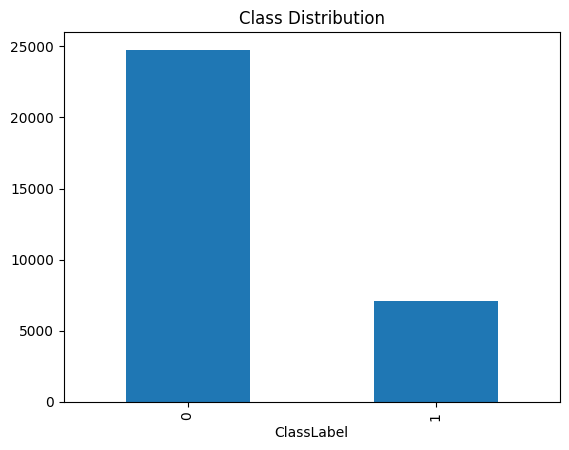

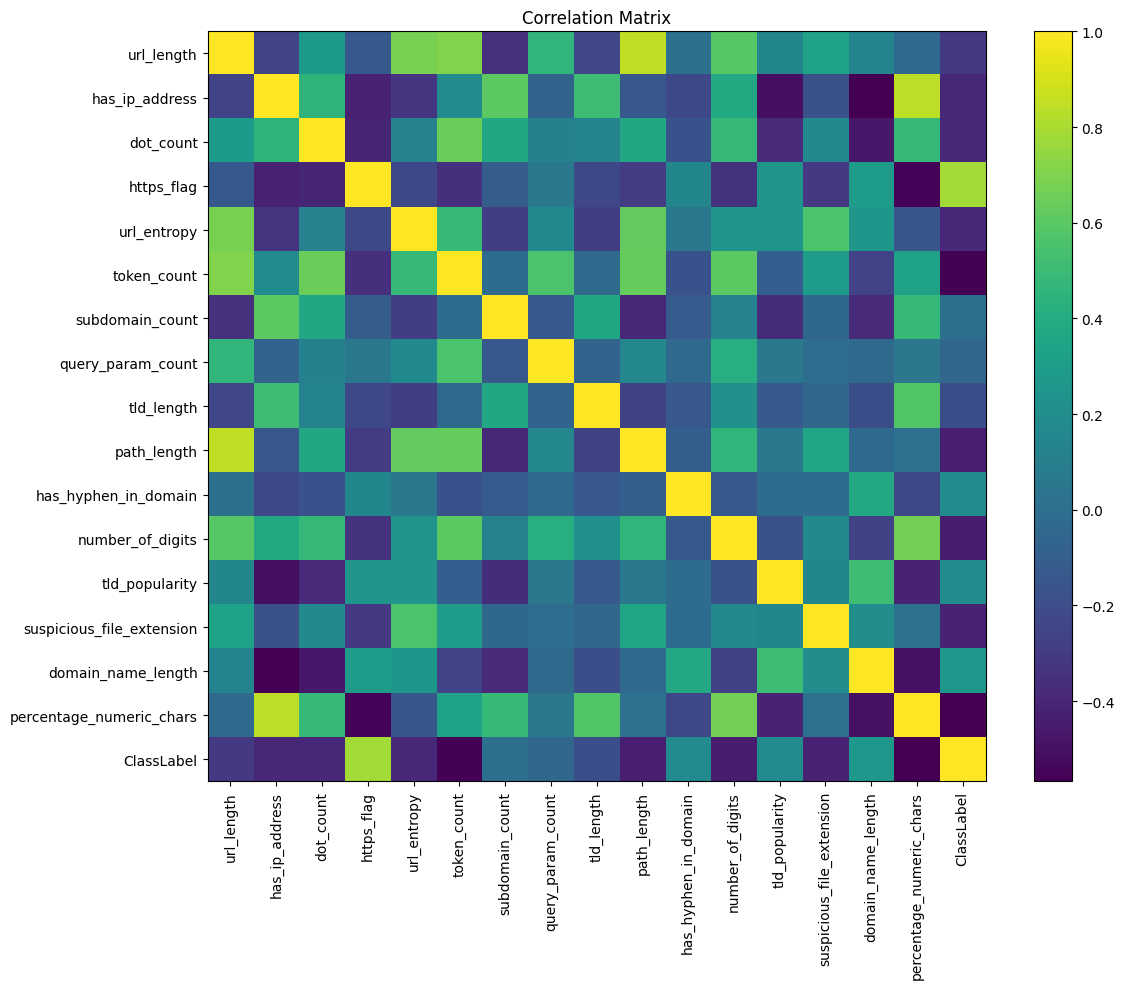

In [ ]:
df[TARGET].value_counts().sort_index().plot(kind="bar")
plt.title("Class Distribution")
plt.show()

corr=df[features+[TARGET]].corr(numeric_only=True)
plt.figure(figsize=(12,10))
plt.imshow(corr,aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)),corr.columns,rotation=90)
plt.yticks(range(len(corr.columns)),corr.columns)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


## 5. Structural-group 80/20 holdout


In [ ]:
def qbin(s,q=5):
    s=s.fillna(s.median())
    try:
        return pd.qcut(s,q=q,duplicates="drop").astype(str)
    except:
        return pd.cut(s,bins=q,duplicates="drop").astype(str)

parts=[]
for c in ["has_ip_address","https_flag","has_hyphen_in_domain","suspicious_file_extension"]:
    if c in df.columns:
        parts.append(df[c].fillna(-1).astype(str))
for c in ["url_length","dot_count","subdomain_count","query_param_count",
          "path_length","number_of_digits","domain_name_length",
          "token_count","url_entropy","percentage_numeric_chars"]:
    if c in df.columns:
        parts.append(qbin(df[c]))

groups=parts[0].astype(str)
for p in parts[1:]:
    groups=groups+"|"+p.astype(str)

X=df[features].copy()
y=df[TARGET].copy()

tr,te=next(GroupShuffleSplit(
    n_splits=1,test_size=.20,random_state=RANDOM_STATE
).split(X,y,groups=groups))

X_train_raw=X.iloc[tr].copy()
X_test_raw=X.iloc[te].copy()
y_train_raw=y.iloc[tr].copy()
y_test=y.iloc[te].copy()

imputer=SimpleImputer(strategy="median")
X_train=pd.DataFrame(imputer.fit_transform(X_train_raw),columns=features)
X_test=pd.DataFrame(imputer.transform(X_test_raw),columns=features)

print("Train:",X_train.shape," Test:",X_test.shape)
print("Group overlap:",len(set(groups.iloc[tr]) & set(groups.iloc[te])))
print("Train distribution %"); print(y_train_raw.value_counts(normalize=True)*100)
print("Test distribution %"); print(y_test.value_counts(normalize=True)*100)


Train: (27559, 16)  Test: (4249, 16)
Group overlap: 0
Train distribution %
ClassLabel
0    77.78947
1    22.21053
Name: proportion, dtype: float64
Test distribution %
ClassLabel
0    77.924217
1    22.075783
Name: proportion, dtype: float64


## 6. Evaluation helpers


In [ ]:
baseline_rows=[]
tuned_rows=[]
gap_rows=[]

def metrics(name,ytrue,pred,score=None,tm=None):
    return {
        "Model":name,
        "Accuracy":accuracy_score(ytrue,pred),
        "Balanced_Accuracy":balanced_accuracy_score(ytrue,pred),
        "Precision_Phishing":precision_score(ytrue,pred,pos_label=0,zero_division=0),
        "Recall_Phishing":recall_score(ytrue,pred,pos_label=0,zero_division=0),
        "F1_Phishing":f1_score(ytrue,pred,pos_label=0,zero_division=0),
        "MCC":matthews_corrcoef(ytrue,pred),
        "ROC_AUC":np.nan if score is None else roc_auc_score((np.asarray(ytrue)==0).astype(int),score),
        "Time_sec":tm
    }

def evaluate(name,model,Xte,yte,store,tm=None):
    pred=model.predict(Xte)
    score=None
    if hasattr(model,"predict_proba"):
        pp=model.predict_proba(Xte)
        score=pp[:,list(model.classes_).index(0)]
    r=metrics(name,yte,pred,score,tm)
    store.append(r)
    print(r)
    return r

def generalization_gap(name,model,Xtr,ytr,Xte,yte):
    trp=model.predict(Xtr); tep=model.predict(Xte)
    gap_rows.append({
        "Model":name,
        "Train_Accuracy":accuracy_score(ytr,trp),
        "Test_Accuracy":accuracy_score(yte,tep),
        "Accuracy_Gap":accuracy_score(ytr,trp)-accuracy_score(yte,tep),
        "Train_Balanced_Accuracy":balanced_accuracy_score(ytr,trp),
        "Test_Balanced_Accuracy":balanced_accuracy_score(yte,tep),
        "Balanced_Gap":balanced_accuracy_score(ytr,trp)-balanced_accuracy_score(yte,tep)
    })


# PHASE A - Five base ML models without augmentation


## 7. Define regularized baseline models


In [ ]:
base_models={
"Logistic Regression":Pipeline([
    ("scale",StandardScaler()),
    ("model",LogisticRegression(
        solver="saga",penalty="l2",C=.2,max_iter=3000,random_state=42
    ))
]),
"SVM":Pipeline([
    ("scale",StandardScaler()),
    ("model",SVC(C=.5,gamma="scale",probability=True,random_state=42))
]),
"Decision Tree":DecisionTreeClassifier(
    max_depth=7,min_samples_split=15,min_samples_leaf=8,
    ccp_alpha=.0005,random_state=42
),
"Random Forest":RandomForestClassifier(
    n_estimators=250,max_depth=10,min_samples_split=10,
    min_samples_leaf=5,max_features="sqrt",ccp_alpha=.0001,
    n_jobs=-1,random_state=42
),
"XGBoost":XGBClassifier(
    n_estimators=250,max_depth=4,learning_rate=.04,min_child_weight=5,
    subsample=.8,colsample_bytree=.7,reg_alpha=.2,reg_lambda=3,
    eval_metric="logloss",n_jobs=-1,random_state=42
)
}


## 8. Baseline train/test


In [ ]:
fitted_baseline={}
for n,m in base_models.items():
    st=time.perf_counter(); m.fit(X_train,y_train_raw.reset_index(drop=True)); tm=time.perf_counter()-st
    fitted_baseline[n]=m
    evaluate(n,m,X_test,y_test,baseline_rows,tm)
    generalization_gap("Baseline "+n,m,X_train,y_train_raw.reset_index(drop=True),X_test,y_test)

baseline_base_table=pd.DataFrame(baseline_rows)
display(baseline_base_table)


{'Model': 'Logistic Regression', 'Accuracy': 0.9778771475641327, 'Balanced_Accuracy': 0.9804563711193354, 'Precision_Phishing': 0.9956856702619414, 'Recall_Phishing': 0.9758381153729991, 'F1_Phishing': 0.9856619890176938, 'MCC': 0.9381899037239401, 'ROC_AUC': 0.9946546982050528, 'Time_sec': 9.753724505000037}
{'Model': 'SVM', 'Accuracy': 0.9858790303600847, 'Balanced_Accuracy': 0.9875009579105379, 'Precision_Phishing': 0.9972468644845518, 'Recall_Phishing': 0.9845967985502869, 'F1_Phishing': 0.9908814589665653, 'MCC': 0.9599883894088193, 'ROC_AUC': 0.9975081446544728, 'Time_sec': 16.345122101000015}
{'Model': 'Decision Tree', 'Accuracy': 0.9955283596140269, 'Balanced_Accuracy': 0.9940744781077999, 'Precision_Phishing': 0.9975816203143894, 'Recall_Phishing': 0.9966777408637874, 'F1_Phishing': 0.9971294757516241, 'MCC': 0.9870197972107079, 'ROC_AUC': 0.9990541639646613, 'Time_sec': 0.07463306800002556}
{'Model': 'Random Forest', 'Accuracy': 0.9962344080960226, 'Balanced_Accuracy': 0.9914

,Model,Accuracy,Balanced_Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing,MCC,ROC_AUC,Time_sec
0,Logistic Regression,0.977877,0.980456,0.995686,0.975838,0.985662,0.938190,0.994655,9.753725
1,SVM,0.985879,0.987501,0.997247,0.984597,0.990881,0.959988,0.997508,16.345122
2,Decision Tree,0.995528,0.994074,0.997582,0.996678,0.997129,0.987020,0.999054,0.074633
3,Random Forest,0.996234,0.991471,0.995191,1.000000,0.997590,0.989048,0.999627,4.351447
4,XGBoost,0.997176,0.994367,0.996987,0.999396,0.998190,0.991781,0.999638,4.185719


# PHASE B - Hyperparameter optimization of five base models


In [ ]:
phish_recall=make_scorer(recall_score,pos_label=0,zero_division=0)


## 9. Tune Logistic Regression


In [ ]:
lr_search=RandomizedSearchCV(
    Pipeline([("scale",StandardScaler()),("model",LogisticRegression(solver="saga",max_iter=4000,random_state=42))]),
    {"model__C":[.005,.01,.02,.05,.1,.2,.5,1],
     "model__penalty":["l1","l2","elasticnet"],
     "model__l1_ratio":[.1,.3,.5,.7,.9],
     "model__class_weight":[None,"balanced"]},
    n_iter=20,cv=5,scoring=phish_recall,n_jobs=-1,random_state=42
)
lr_search.fit(X_train,y_train_raw.reset_index(drop=True)); best_lr=lr_search.best_estimator_
print(lr_search.best_params_)


{'model__penalty': 'elasticnet', 'model__l1_ratio': 0.3, 'model__class_weight': None, 'model__C': 0.5}


## 10. Tune SVM


In [ ]:
sv_idx=X_train.sample(min(25000,len(X_train)),random_state=42).index
svm_search=RandomizedSearchCV(
    Pipeline([("scale",StandardScaler()),("model",SVC(probability=True,random_state=42))]),
    {"model__C":[.05,.1,.25,.5,1,2],
     "model__gamma":["scale","auto",.001,.005,.01,.05],
     "model__kernel":["rbf","poly"],
     "model__class_weight":[None,"balanced"]},
    n_iter=16,cv=3,scoring=phish_recall,n_jobs=-1,random_state=42
)
svm_search.fit(X_train.loc[sv_idx],y_train_raw.reset_index(drop=True).loc[sv_idx])
best_svm=svm_search.best_estimator_; best_svm.fit(X_train,y_train_raw.reset_index(drop=True))
print(svm_search.best_params_)


{'model__kernel': 'poly', 'model__gamma': 'auto', 'model__class_weight': None, 'model__C': 0.25}


## 11. Tune Decision Tree


In [ ]:
dt_search=RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"max_depth":[3,4,5,6,7,8,10,12],
     "min_samples_split":[10,20,30,50],
     "min_samples_leaf":[5,10,15,20],
     "ccp_alpha":[0,.0001,.0005,.001,.005],
     "criterion":["gini","entropy"],
     "class_weight":[None,"balanced"]},
    n_iter=25,cv=5,scoring=phish_recall,n_jobs=-1,random_state=42
)
dt_search.fit(X_train,y_train_raw.reset_index(drop=True)); best_dt=dt_search.best_estimator_
print(dt_search.best_params_)


{'min_samples_split': 20, 'min_samples_leaf': 15, 'max_depth': 12, 'criterion': 'gini', 'class_weight': None, 'ccp_alpha': 0.005}


## 12. Tune Random Forest


In [ ]:
rf_search=RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1,random_state=42),
    {"n_estimators":[150,200,250,300,400],
     "max_depth":[5,7,9,11,13],
     "min_samples_split":[10,20,30],
     "min_samples_leaf":[3,5,8,12,15],
     "max_features":["sqrt","log2"],
     "ccp_alpha":[0,.0001,.0005,.001],
     "class_weight":[None,"balanced","balanced_subsample"]},
    n_iter=24,cv=5,scoring=phish_recall,n_jobs=-1,random_state=42
)
rf_search.fit(X_train,y_train_raw.reset_index(drop=True)); best_rf=rf_search.best_estimator_
print(rf_search.best_params_)


{'n_estimators': 150, 'min_samples_split': 30, 'min_samples_leaf': 12, 'max_features': 'sqrt', 'max_depth': 5, 'class_weight': None, 'ccp_alpha': 0.0005}


## 13. Tune XGBoost + early stopping


In [ ]:
xgb_search=RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss",n_jobs=-1,random_state=42),
    {"n_estimators":[100,150,200,250,300,400],
     "max_depth":[2,3,4,5],
     "learning_rate":[.01,.02,.03,.05,.08],
     "min_child_weight":[3,5,8,10],
     "subsample":[.6,.7,.8,.9],
     "colsample_bytree":[.5,.6,.7,.8],
     "gamma":[0,.05,.1,.2],
     "reg_alpha":[.05,.1,.2,.5,1],
     "reg_lambda":[1,2,3,5,8]},
    n_iter=25,cv=5,scoring=phish_recall,n_jobs=-1,random_state=42
)
xgb_search.fit(X_train,y_train_raw.reset_index(drop=True))
p=xgb_search.best_estimator_.get_params()
p["early_stopping_rounds"]=20
best_xgb=XGBClassifier(**p)
Xa,Xv,ya,yv=train_test_split(X_train,y_train_raw.reset_index(drop=True),test_size=.15,stratify=y_train_raw.reset_index(drop=True),random_state=42)
best_xgb.fit(Xa,ya,eval_set=[(Xv,yv)],verbose=False)
print(xgb_search.best_params_)


{'subsample': 0.6, 'reg_lambda': 1, 'reg_alpha': 1, 'n_estimators': 150, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.02, 'gamma': 0.2, 'colsample_bytree': 0.8}


## 14. Tuned base-model results and ranking


In [ ]:
tuned_base={"Logistic Regression":best_lr,"SVM":best_svm,"Decision Tree":best_dt,"Random Forest":best_rf,"XGBoost":best_xgb}
validation_rank_rows=[]

# independent validation used only to rank models for stacking/blending architecture
R_Xtrain,R_Xval,R_ytrain,R_yval=train_test_split(
    X_train,y_train_raw.reset_index(drop=True),test_size=.20,
    stratify=y_train_raw.reset_index(drop=True),random_state=2026
)

for n,m0 in tuned_base.items():
    m=clone(m0)
    # XGB clone with early stopping attribute can fit without eval set; remove if necessary
    try:
        m.fit(R_Xtrain,R_ytrain)
    except:
        if n=="XGBoost":
            p=m0.get_params(); p.pop("early_stopping_rounds",None)
            m=XGBClassifier(**p); m.fit(R_Xtrain,R_ytrain)
        else:
            raise
    pred=m.predict(R_Xval)
    validation_rank_rows.append({
        "Model":n,
        "Balanced_Accuracy":balanced_accuracy_score(R_yval,pred),
        "F1_Phishing":f1_score(R_yval,pred,pos_label=0,zero_division=0),
        "Recall_Phishing":recall_score(R_yval,pred,pos_label=0,zero_division=0)
    })

ranking=pd.DataFrame(validation_rank_rows).sort_values(
    ["Balanced_Accuracy","F1_Phishing","Recall_Phishing"],ascending=False
).reset_index(drop=True)
display(ranking)

best_name=ranking.iloc[0].Model
base_names=ranking.iloc[1:4].Model.tolist()
print("Meta-model:",best_name)
print("Stacking/Blending base models:",base_names)

for n,m in tuned_base.items():
    st=time.perf_counter()
    # already fitted, just record test
    tm=time.perf_counter()-st
    evaluate("Tuned "+n,m,X_test,y_test,tuned_rows,tm)
    generalization_gap("Tuned "+n,m,X_train,y_train_raw.reset_index(drop=True),X_test,y_test)


,Model,Balanced_Accuracy,F1_Phishing,Recall_Phishing
0,SVM,0.989673,0.995218,0.994869
1,Logistic Regression,0.987108,0.992632,0.989739
2,Decision Tree,0.970063,0.991443,0.999767
3,Random Forest,0.970063,0.991443,0.999767
4,XGBoost,0.970063,0.991443,0.999767


Meta-model: SVM
Stacking/Blending base models: ['Logistic Regression', 'Decision Tree', 'Random Forest']
{'Model': 'Tuned Logistic Regression', 'Accuracy': 0.97999529301012, 'Balanced_Accuracy': 0.9821975143911972, 'Precision_Phishing': 0.9960024600246002, 'Recall_Phishing': 0.9782543038356992, 'F1_Phishing': 0.9870486058205089, 'MCC': 0.9438720479470756, 'ROC_AUC': 0.9945603560915706, 'Time_sec': 1.1219999578315765e-06}
{'Model': 'Tuned SVM', 'Accuracy': 0.9858790303600847, 'Balanced_Accuracy': 0.9871189206489449, 'Precision_Phishing': 0.9969428309385509, 'Recall_Phishing': 0.9848988221081244, 'F1_Phishing': 0.9908842297174111, 'MCC': 0.959922794245938, 'ROC_AUC': 0.9970229106441733, 'Time_sec': 6.300001587078441e-07}
{'Model': 'Tuned Decision Tree', 'Accuracy': 0.9778771475641327, 'Balanced_Accuracy': 0.9498933901918977, 'Precision_Phishing': 0.9723935389133627, 'Recall_Phishing': 1.0, 'F1_Phishing': 0.9860035735556879, 'MCC': 0.9353859372712738, 'ROC_AUC': 0.9498933901918977, 'Time_

# PHASE C - Dynamic Stacking and Blending


## 15. Build Stacking using ranks 2-4 as bases and rank 1 as meta


In [ ]:
def safe_clone_model(name):
    m=tuned_base[name]
    if name=="XGBoost":
        p=m.get_params(); p.pop("early_stopping_rounds",None)
        return XGBClassifier(**p)
    return clone(m)

stack_bases=[(n.replace(" ","_"),safe_clone_model(n)) for n in base_names]
meta_model=safe_clone_model(best_name)

stack_model=StackingClassifier(
    estimators=stack_bases,
    final_estimator=meta_model,
    cv=3,
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=-1
)

st=time.perf_counter(); stack_model.fit(X_train,y_train_raw.reset_index(drop=True)); stack_time=time.perf_counter()-st
stack_result=evaluate("Stacking",stack_model,X_test,y_test,tuned_rows,stack_time)
generalization_gap("Stacking",stack_model,X_train,y_train_raw.reset_index(drop=True),X_test,y_test)


{'Model': 'Stacking', 'Accuracy': 0.9778771475641327, 'Balanced_Accuracy': 0.9498933901918977, 'Precision_Phishing': 0.9723935389133627, 'Recall_Phishing': 1.0, 'F1_Phishing': 0.9860035735556879, 'MCC': 0.9353859372712738, 'ROC_AUC': 0.9529232853723358, 'Time_sec': 31.280979952000052}


## 16. Blending using the same bases and same meta-model


In [ ]:
# hold out a blend-validation partition from training
BX_train,BX_blend,By_train,By_blend=train_test_split(
    X_train,y_train_raw.reset_index(drop=True),
    test_size=.20,stratify=y_train_raw.reset_index(drop=True),random_state=2027
)

blend_bases={}
blend_train_meta=[]
blend_test_meta=[]

for n in base_names:
    m=safe_clone_model(n)
    m.fit(BX_train,By_train)
    blend_bases[n]=m
    blend_train_meta.append(m.predict_proba(BX_blend)[:,1])
    blend_test_meta.append(m.predict_proba(X_test)[:,1])

M_train=np.column_stack(blend_train_meta)
M_test=np.column_stack(blend_test_meta)

blend_meta=safe_clone_model(best_name)
st=time.perf_counter()
blend_meta.fit(M_train,By_blend)
blend_time=time.perf_counter()-st
blend_pred=blend_meta.predict(M_test)
blend_score=blend_meta.predict_proba(M_test)[:,0] if hasattr(blend_meta,"predict_proba") else None
blend_result=metrics("Blending",y_test,blend_pred,blend_score,blend_time)
print(blend_result)


{'Model': 'Blending', 'Accuracy': 0.9795245940221229, 'Balanced_Accuracy': 0.9708164102471635, 'Precision_Phishing': 0.9873035066505441, 'Recall_Phishing': 0.986408939897312, 'F1_Phishing': 0.9868560205469105, 'MCC': 0.9405568155338654, 'ROC_AUC': 0.998485052409781, 'Time_sec': 0.12812612800007628}


## 17. Primary six-model table + blending comparison


In [ ]:
# Six primary = five tuned base classifiers + Stacking
primary_six=pd.DataFrame(tuned_rows)
primary_six=primary_six[primary_six.Model.isin(
    ["Tuned Logistic Regression","Tuned SVM","Tuned Decision Tree",
     "Tuned Random Forest","Tuned XGBoost","Stacking"]
)]
display(primary_six)

ensemble_comparison=pd.DataFrame([stack_result,blend_result])
display(ensemble_comparison)


,Model,Accuracy,Balanced_Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing,MCC,ROC_AUC,Time_sec
0,Tuned Logistic Regression,0.979995,0.982198,0.996002,0.978254,0.987049,0.943872,0.994560,1.122000e-06
1,Tuned SVM,0.985879,0.987119,0.996943,0.984899,0.990884,0.959923,0.997023,6.300002e-07
2,Tuned Decision Tree,0.977877,0.949893,0.972394,1.000000,0.986004,0.935386,0.949893,9.379999e-07
3,Tuned Random Forest,0.977877,0.949893,0.972394,1.000000,0.986004,0.935386,0.998686,7.079998e-07
4,Tuned XGBoost,0.977877,0.949893,0.972394,1.000000,0.986004,0.935386,0.999091,7.459998e-07
5,Stacking,0.977877,0.949893,0.972394,1.000000,0.986004,0.935386,0.952923,3.128098e+01


,Model,Accuracy,Balanced_Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing,MCC,ROC_AUC,Time_sec
0,Stacking,0.977877,0.949893,0.972394,1.000000,0.986004,0.935386,0.952923,31.280980
1,Blending,0.979525,0.970816,0.987304,0.986409,0.986856,0.940557,0.998485,0.128126


# PHASE D - Three data augmentation techniques


## 18. Compare Random Oversampling, SMOTE and ADASYN


In [ ]:
augmenters={
    "Random Oversampling":RandomOverSampler(random_state=42),
    "SMOTE":SMOTE(random_state=42,k_neighbors=5),
    "ADASYN":ADASYN(random_state=42,n_neighbors=5)
}

augmentation_rows=[]

# Use best tuned standalone model for clean augmentation comparison
for aug_name,aug in augmenters.items():
    X_aug,y_aug=aug.fit_resample(X_train,y_train_raw.reset_index(drop=True))
    X_aug=pd.DataFrame(X_aug,columns=features)
    y_aug=pd.Series(y_aug)

    m=safe_clone_model(best_name)
    # For XGB early stop removed by safe_clone_model.
    st=time.perf_counter(); m.fit(X_aug,y_aug); tm=time.perf_counter()-st
    pred=m.predict(X_test)
    score=m.predict_proba(X_test)[:,0] if hasattr(m,"predict_proba") else None
    r=metrics(best_name+" + "+aug_name,y_test,pred,score,tm)
    r["Augmentation"]=aug_name
    r["Train_Class0"]=int((y_aug==0).sum())
    r["Train_Class1"]=int((y_aug==1).sum())
    augmentation_rows.append(r)

augmentation_table=pd.DataFrame(augmentation_rows)
display(augmentation_table)


,Model,Accuracy,Balanced_Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing,MCC,ROC_AUC,Time_sec,Augmentation,Train_Class0,Train_Class1
0,SVM + Random Oversampling,0.979289,0.985565,0.999071,0.974328,0.986544,0.943027,0.996824,19.219296,Random Oversampling,21438,21438
1,SVM + SMOTE,0.979525,0.985334,0.998762,0.974932,0.986703,0.943529,0.996649,18.542002,SMOTE,21438,21438
2,SVM + ADASYN,0.975053,0.982847,0.999066,0.968892,0.983747,0.932183,0.995937,25.009728,ADASYN,21438,21457


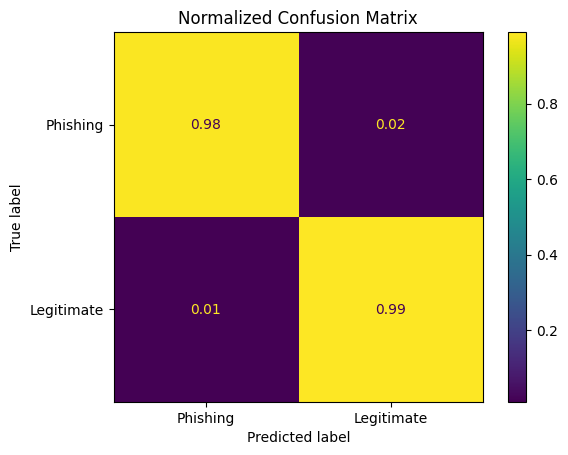

In [ ]:
pred=best_xai_model.predict(X_test)
cm=confusion_matrix(y_test,pred,labels=[0,1],normalize="true")
ConfusionMatrixDisplay(cm,display_labels=["Phishing","Legitimate"]).plot(values_format=".2f")
plt.title("Normalized Confusion Matrix")
plt.show()
